In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
df=pd.read_csv(r"C:\Users\20251BCD0037\Downloads\titanic3.csv")


In [ ]:
df["Title"]=df['name'].str.extract('([A-Za-z]+)\.',expand=True)
df.head()


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest,Title
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.00,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO",Miss
1,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON",Master
2,1,0,"Allison, Miss. Helen Loraine",female,2.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",Miss
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.00,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON",Mr
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",Mrs


In [ ]:
df['Title'].dvalue_counts()

Title
Mr          757
Miss        260
Mrs         197
Master       61
Rev           8
Dr            8
Col           4
Mlle          2
Ms            2
Major         2
Capt          1
Sir           1
Dona          1
Jonkheer      1
Countess      1
Don           1
Mme           1
Lady          1
Name: count, dtype: int64

In [ ]:
mapping={'Mlle':'Miss','Major':'Mr','Col':'Mr','Sir':'Mr','Don':'Mr','Mme':'Mrs','Jonkheer':'Mr',
         'Lady':'Mrs','Capt':'Mr','Countess':'Mrs','Ms':'Miss','Dona':'Mrs'}
df.replace({'Title':mapping},inplace=True)


In [ ]:
df['Title'].value_counts()

Title
Mr        767
Miss      264
Mrs       201
Master     61
Dr          8
Rev         8
Name: count, dtype: int64

In [ ]:
title_ages=dict(df.groupby('Title')['age'].median())

In [ ]:
df['age_med']=df['Title'].apply(lambda x:title_ages[x])


In [ ]:
df.fillna({'age': df['age_med']}, inplace=True)
del df['age_med']

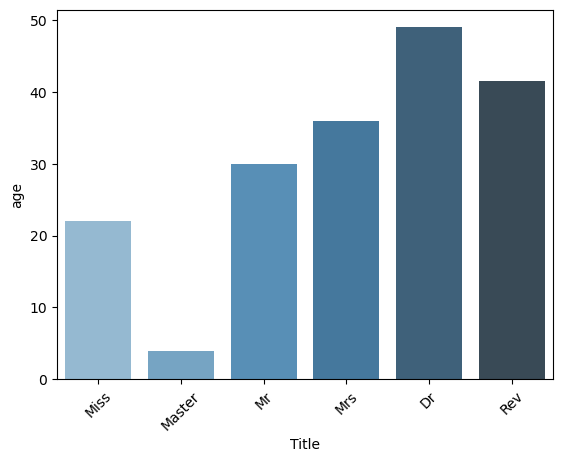

In [ ]:
sns.barplot(x ='Title',y='age',data=df,estimator=np.median,errorbar=None,palette='Blues_d',hue='Title')
plt.xticks(rotation=45)
plt.show()

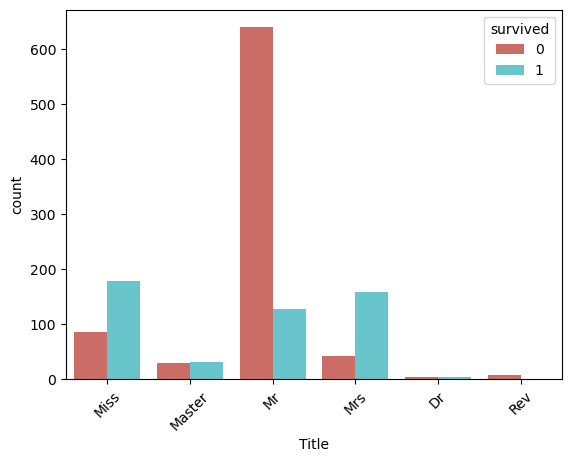

In [ ]:
sns.countplot(x='Title',data=df,palette='hls',hue='survived')
plt.xticks(rotation=45)
plt.show()